The K-Means walkthrough ended on three failures it could not fix: stretched clusters,
clusters of very different sizes, and any question of *how confident* an assignment is.

All three come from the same two restrictions. K-means represents a cluster by a **single
point**, and assigns every sample to exactly one cluster &mdash; **hard** assignment.

A Gaussian mixture removes both. A cluster becomes a full **distribution**:

$$p(\mathbf{x}) = \sum_{k=1}^{K}\pi_k\,\mathcal{N}(\mathbf{x}\mid\boldsymbol{\mu}_k,\Sigma_k),
\qquad \sum_k \pi_k = 1$$

with a mixing weight $\pi_k$ (how large), a mean $\boldsymbol{\mu}_k$ (where), and a
**covariance** $\Sigma_k$ (what shape and orientation). Assignment becomes a probability.

Fitting it uses **EM**, which is the same alternating pattern as Lloyd's algorithm with
one substitution: *soft* responsibilities instead of hard assignments. In fact k-means is
the limiting case, and that is shown numerically at the end.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The same 20 EEG epochs as the K-Means walkthrough, with the labels again withheld, so the
two methods can be compared directly on identical points.

In [2]:
# ----------------------------------------------------------------------------
#  20 EEG epochs, two features, two classes. Small enough to print in full,
#  and deliberately NOT perfectly separable.
# ----------------------------------------------------------------------------
feat2 = ["spike_rate", "line_length"]

P = np.array([
    [1.0, 12.0], [1.6, 15.0], [0.7, 11.0], [2.1, 18.0], [1.3, 14.0],
    [2.6, 21.0], [0.9, 16.0], [1.9, 13.0], [3.1, 24.0], [2.3, 17.0],
    [6.2, 41.0], [7.1, 47.0], [5.4, 38.0], [8.0, 52.0], [6.7, 44.0],
    [5.9, 49.0], [7.6, 39.0], [6.0, 35.0], [4.7, 43.0], [8.3, 46.0],
])
t2 = np.array([0]*10 + [1]*10)

# two deliberate overlaps, so no straight line separates the data perfectly
P[9]  = [4.4, 33.0]      # a class-0 epoch pushed into class-1 territory
t2[9] = 0
P[18] = [3.6, 27.0]      # a class-1 epoch pushed down toward class 0
t2[18] = 1

n2 = len(P)
ep_ids = [f"ep{i:02d}" for i in range(n2)]
cls_names = ["no seizure", "seizure"]

print(f"{n2} epochs x {P.shape[1]} features, classes {np.bincount(t2).tolist()}\n")
hdr = f"{'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'class':>6}  {'label':>12}"
print(hdr); print("-" * len(hdr))
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {t2[i]:>6}  "
          f"{cls_names[t2[i]]:>12}")
print("-" * len(hdr))
print(f"\nfeature means : {np.round(P.mean(axis=0), 3)}")
print(f"feature stds  : {np.round(P.std(axis=0), 3)}")
print(f"\nNote the scales: {feat2[1]} spans ~{P[:,1].ptp() if hasattr(P[:,1],'ptp') else np.ptp(P[:,1]):.0f} "
      f"while {feat2[0]} spans ~{np.ptp(P[:,0]):.0f}.")
print("Any algorithm that measures DISTANCE will be dominated by the larger one")
print("unless the features are scaled - that matters for KNN and SVM below.")

20 epochs x 2 features, classes [10, 10]

    id   spike_rate   line_length   class         label
-------------------------------------------------------
  ep00          1.0          12.0       0    no seizure
  ep01          1.6          15.0       0    no seizure
  ep02          0.7          11.0       0    no seizure
  ep03          2.1          18.0       0    no seizure
  ep04          1.3          14.0       0    no seizure
  ep05          2.6          21.0       0    no seizure
  ep06          0.9          16.0       0    no seizure
  ep07          1.9          13.0       0    no seizure
  ep08          3.1          24.0       0    no seizure
  ep09          4.4          33.0       0    no seizure
  ep10          6.2          41.0       1       seizure
  ep11          7.1          47.0       1       seizure
  ep12          5.4          38.0       1       seizure
  ep13          8.0          52.0       1       seizure
  ep14          6.7          44.0       1       seizure
  ep15

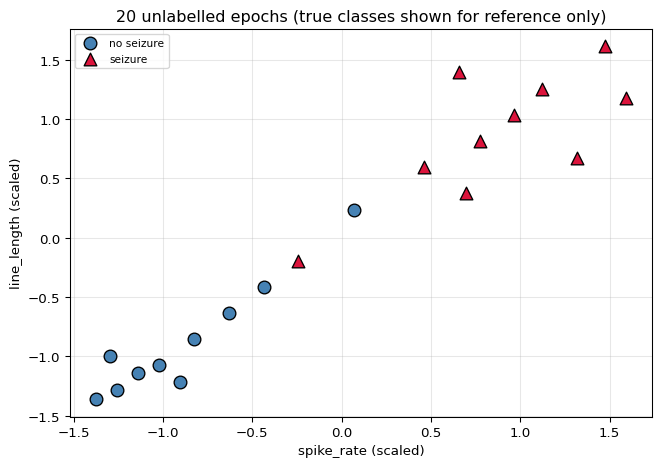

K = 2 components, D = 2 dimensions

parameters per component: 1 weight + 2 mean + 3 covariance = 6
total (minus one, since the weights must sum to 1): 11

k-means, by comparison, has only 4 parameters - just the centres.


In [3]:
def plot2d(ax=None, scaled=False, title="", legend=True):
    A = Pz if scaled else P
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.set(xlabel=feat2[0] + (" (scaled)" if scaled else ""),
           ylabel=feat2[1] + (" (scaled)" if scaled else ""), title=title)
    if legend:
        ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    return ax

Pz = (P - P.mean(axis=0)) / P.std(axis=0)
K = 2
D = 2
plot2d(scaled=True, title="20 unlabelled epochs (true classes shown for reference only)")
plt.tight_layout(); plt.show()
print(f"K = {K} components, D = {D} dimensions\n")
print(f"parameters per component: 1 weight + {D} mean + {D*(D+1)//2} covariance = "
      f"{1 + D + D*(D+1)//2}")
print(f"total (minus one, since the weights must sum to 1): "
      f"{K*(1 + D + D*(D+1)//2) - 1}")
print(f"\nk-means, by comparison, has only {K*D} parameters - just the centres.")

---
# 2. The Multivariate Gaussian

$$\mathcal{N}(\mathbf{x}\mid\boldsymbol{\mu},\Sigma) =
\frac{1}{(2\pi)^{D/2}\lvert\Sigma\rvert^{1/2}}
\exp\!\left(-\tfrac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^\top\Sigma^{-1}(\mathbf{x}-\boldsymbol{\mu})\right)$$

The covariance is what k-means lacks. Its **off-diagonal** entries let the ellipse tilt;
its diagonal lets the axes have different widths. That single matrix is the difference
between a circle and an arbitrarily oriented ellipse.

The quadratic form in the exponent is the squared **Mahalanobis distance** &mdash; distance
measured in units of the cluster's own spread, so a point far along a wide direction can
be *closer* than one nearer along a narrow direction.

two covariances, same mean

circular (2, 2) =
            0 |   +1.00    +0.00
            1 |   +0.00    +1.00

tilted (off-diagonal 0.8) (2, 2) =
            0 |   +1.00    +0.80
            1 |   +0.80    +1.00

determinants: circular 1.0000, tilted 0.3600


the point [1.5 1.5] under each

   circular:
      Sigma^-1 =
[[1. 0.]
           [0. 1.]]
      Mahalanobis^2 = d^T Sigma^-1 d = 4.500000
      density = exp(-2.2500) / sqrt((2pi)^2 * 1.0000) = 0.01677481
      Euclidean^2 (what k-means uses) = 4.500000

   tilted:
      Sigma^-1 =
[[ 2.7778 -2.2222]
           [-2.2222  2.7778]]
      Mahalanobis^2 = d^T Sigma^-1 d = 2.500000
      density = exp(-1.2500) / sqrt((2pi)^2 * 0.3600) = 0.07599776
      Euclidean^2 (what k-means uses) = 4.500000

Euclidean distance is identical in both cases; the DENSITY is not.
Under the tilted Gaussian this point lies along the direction of high
variance, so it is unremarkable. k-means could never make that
distinction - it has no Sigma.


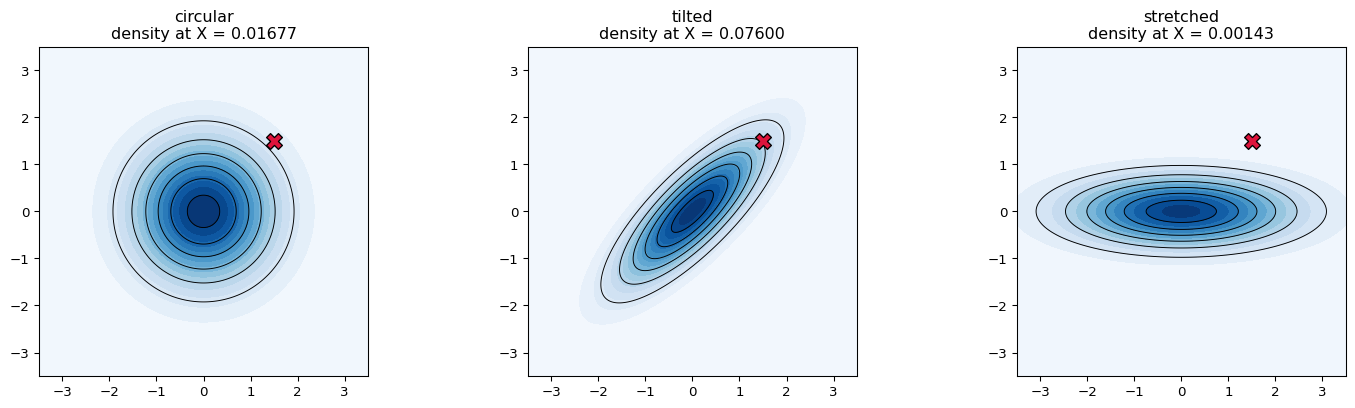

The red X is the same point in all three. Its density differs by orders
of magnitude - and the density is what decides cluster membership.


In [4]:
def gauss(Xm, mu, Sig):
    Dm = len(mu)
    diff = Xm - mu
    inv = np.linalg.inv(Sig)
    q = np.einsum("ij,jk,ik->i", diff, inv, diff)
    return np.exp(-0.5*q) / np.sqrt((2*np.pi)**Dm * np.linalg.det(Sig))

mu_demo = np.array([0.0, 0.0])
Sig_circle = np.array([[1.0, 0.0], [0.0, 1.0]])
Sig_tilt = np.array([[1.0, 0.8], [0.8, 1.0]])

print("two covariances, same mean\n")
show_matrix(Sig_circle, "circular", fmt="{:+7.2f}")
print()
show_matrix(Sig_tilt, "tilted (off-diagonal 0.8)", fmt="{:+7.2f}")
print(f"\ndeterminants: circular {np.linalg.det(Sig_circle):.4f}, "
      f"tilted {np.linalg.det(Sig_tilt):.4f}")

pt = np.array([[1.5, 1.5]])
print(f"\n\nthe point {pt[0]} under each\n")
for nm, S in [("circular", Sig_circle), ("tilted", Sig_tilt)]:
    d = pt[0] - mu_demo
    inv = np.linalg.inv(S)
    q = float(d @ inv @ d)
    print(f"   {nm}:")
    print(f"      Sigma^-1 =\n{np.array2string(np.round(inv,4), prefix='          ')}")
    print(f"      Mahalanobis^2 = d^T Sigma^-1 d = {q:.6f}")
    print(f"      density = exp(-{q/2:.4f}) / sqrt((2pi)^2 * {np.linalg.det(S):.4f}) "
          f"= {float(gauss(pt, mu_demo, S)[0]):.8f}")
    print(f"      Euclidean^2 (what k-means uses) = {float(d @ d):.6f}\n")
print(f"Euclidean distance is identical in both cases; the DENSITY is not.")
print(f"Under the tilted Gaussian this point lies along the direction of high")
print(f"variance, so it is unremarkable. k-means could never make that")
print(f"distinction - it has no Sigma.")

g, gy = np.meshgrid(np.linspace(-3.5, 3.5, 260), np.linspace(-3.5, 3.5, 260))
G = np.column_stack([g.ravel(), gy.ravel()])
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
for ax, (nm, S) in zip(axes, [("circular", Sig_circle), ("tilted", Sig_tilt),
                              ("stretched", np.array([[2.5, 0.0],[0.0, 0.25]]))]):
    dens = gauss(G, mu_demo, S).reshape(g.shape)
    ax.contourf(g, gy, dens, levels=18, cmap="Blues")
    ax.contour(g, gy, dens, levels=6, colors="k", linewidths=.7)
    ax.scatter([1.5], [1.5], s=140, c="crimson", marker="X", edgecolor="k", zorder=5)
    ax.set(title=f"{nm}\ndensity at X = {float(gauss(pt, mu_demo, S)[0]):.5f}",
           aspect="equal")
plt.tight_layout(); plt.show()
print("The red X is the same point in all three. Its density differs by orders")
print("of magnitude - and the density is what decides cluster membership.")

---
# 3. EM &mdash; Soft Assignment

Two steps, alternating, exactly like Lloyd's algorithm.

**E-step.** Compute the **responsibility** of component $k$ for point $i$ &mdash; the posterior
probability that $i$ came from $k$:

$$\gamma_{ik} = \frac{\pi_k\,\mathcal{N}(\mathbf{x}_i\mid\boldsymbol{\mu}_k,\Sigma_k)}
{\sum_{j}\pi_j\,\mathcal{N}(\mathbf{x}_i\mid\boldsymbol{\mu}_j,\Sigma_j)}
\qquad\text{with}\qquad \sum_k \gamma_{ik} = 1$$

**M-step.** Refit each component using every point, **weighted by its responsibility**:

$$N_k = \sum_i\gamma_{ik}, \qquad
\boldsymbol{\mu}_k = \frac{1}{N_k}\sum_i\gamma_{ik}\mathbf{x}_i, \qquad
\Sigma_k = \frac{1}{N_k}\sum_i\gamma_{ik}(\mathbf{x}_i-\boldsymbol{\mu}_k)(\mathbf{x}_i-\boldsymbol{\mu}_k)^\top,
\qquad \pi_k = \frac{N_k}{n}$$

The difference from k-means is entirely in the word *weighted*. K-means uses
$\gamma \in \{0,1\}$; EM lets it be anything in between, so a point near a boundary
contributes to **both** components in proportion to how well each explains it.

In [5]:
rng = np.random.default_rng(2)
idx0 = rng.choice(n2, K, replace=False)
mus = Pz[idx0].copy()
Sigs = np.array([np.eye(D) for _ in range(K)])
pis = np.full(K, 1.0/K)

def e_step(Xm, mus_, Sigs_, pis_):
    dens = np.column_stack([pis_[k]*gauss(Xm, mus_[k], Sigs_[k]) for k in range(K)])
    tot = dens.sum(axis=1, keepdims=True)
    return dens/tot, float(np.sum(np.log(tot)))

def m_step(Xm, gam):
    Nk = gam.sum(axis=0)
    mus_ = (gam.T @ Xm) / Nk[:, None]
    Sigs_ = []
    for k in range(K):
        d = Xm - mus_[k]
        Sigs_.append((gam[:, k, None, None] * np.einsum("ij,ik->ijk", d, d)).sum(0) / Nk[k]
                     + 1e-6*np.eye(D))
    return mus_, np.array(Sigs_), Nk/len(Xm)

print(f"initial means (two random epochs): {[ep_ids[i] for i in idx0]}\n")
for k in range(K):
    print(f"   mu_{k} = {np.round(mus[k], 4)}   pi_{k} = {pis[k]:.4f}")

gam, ll = e_step(Pz, mus, Sigs, pis)
print(f"\ninitial log-likelihood: {ll:.6f}\n")
print("E-STEP, iteration 1 - responsibilities\n")
print(f"{'id':>6}  {'pi0*N0':>12}  {'pi1*N1':>12}  {'sum':>12}  "
      f"{'gamma_0':>9}  {'gamma_1':>9}  {'confident?':>11}")
print("-" * 80)
for i in range(n2):
    d0 = pis[0]*float(gauss(Pz[i:i+1], mus[0], Sigs[0])[0])
    d1 = pis[1]*float(gauss(Pz[i:i+1], mus[1], Sigs[1])[0])
    conf = "yes" if max(gam[i]) > 0.9 else ("borderline" if max(gam[i]) < 0.7 else "-")
    print(f"{ep_ids[i]:>6}  {d0:>12.6e}  {d1:>12.6e}  {d0+d1:>12.6e}  "
          f"{gam[i,0]:>9.6f}  {gam[i,1]:>9.6f}  {conf:>11}")
print("-" * 80)
print(f"\nevery row sums to 1: {np.allclose(gam.sum(axis=1), 1)}")

i0 = int(np.argmin(np.abs(gam[:,0]-0.5)))
print(f"\nworked example, the most uncertain epoch ({ep_ids[i0]}):")
d0 = pis[0]*float(gauss(Pz[i0:i0+1], mus[0], Sigs[0])[0])
d1 = pis[1]*float(gauss(Pz[i0:i0+1], mus[1], Sigs[1])[0])
print(f"   pi_0 * N(x | mu_0, S_0) = {pis[0]:.4f} * {d0/pis[0]:.6e} = {d0:.6e}")
print(f"   pi_1 * N(x | mu_1, S_1) = {pis[1]:.4f} * {d1/pis[1]:.6e} = {d1:.6e}")
print(f"   gamma_0 = {d0:.6e} / ({d0:.6e} + {d1:.6e}) = {d0/(d0+d1):.6f}")
print(f"   from the array: {gam[i0,0]:.6f}   "
      f"MATCH: {np.isclose(d0/(d0+d1), gam[i0,0])}")
print(f"\n   k-means would force this epoch entirely into one cluster. EM records")
print(f"   that it is {gam[i0,0]:.0%}/{gam[i0,1]:.0%} - and that uncertainty feeds")
print(f"   into the M-step.")

initial means (two random epochs): ['ep05', 'ep15']

   mu_0 = [-0.6319 -0.6343]   pi_0 = 0.5000
   mu_1 = [0.6553 1.3955]   pi_1 = 0.5000

initial log-likelihood: -53.789152

E-STEP, iteration 1 - responsibilities

    id        pi0*N0        pi1*N1           sum    gamma_0    gamma_1   confident?
--------------------------------------------------------------------------------
  ep00  5.293937e-02  3.509963e-04  5.329037e-02   0.993414   0.006586          yes
  ep01  6.709194e-02  9.348445e-04  6.802679e-02   0.986258   0.013742          yes
  ep02  4.649505e-02  2.288812e-04  4.672393e-02   0.995101   0.004899          yes
  ep03  7.625357e-02  2.123583e-03  7.837715e-02   0.972906   0.027094          yes
  ep04  6.152321e-02  6.364842e-04  6.215969e-02   0.989760   0.010240          yes
  ep05  7.957747e-02  4.429342e-03  8.400681e-02   0.947274   0.052726          yes
  ep06  5.981096e-02  6.793876e-04  6.049034e-02   0.988769   0.011231          yes
  ep07  6.479889e-02  7.820655e

In [6]:
mus_n, Sigs_n, pis_n = m_step(Pz, gam)
print("M-STEP, iteration 1\n")
Nk = gam.sum(axis=0)
print(f"effective counts N_k = sum of responsibilities:")
for k in range(K):
    print(f"   N_{k} = {' + '.join(f'{gam[i,k]:.3f}' for i in range(5))} + ... = "
          f"{Nk[k]:.6f}")
print(f"   N_0 + N_1 = {Nk.sum():.6f}  (= n = {n2}): {np.isclose(Nk.sum(), n2)}\n")

for k in range(K):
    print(f"component {k}:")
    print(f"   pi_{k} = N_{k}/n = {Nk[k]:.4f}/{n2} = {pis_n[k]:.6f}")
    num = (gam[:, k, None]*Pz).sum(0)
    print(f"   mu_{k} = (weighted sum) / N_{k}")
    print(f"        = {np.round(num, 4)} / {Nk[k]:.4f} = {np.round(mus_n[k], 6)}")
    print(f"        was {np.round(mus[k], 6)}")
    print(f"   Sigma_{k} =")
    show_matrix(Sigs_n[k], f"      ", fmt="{:+9.5f}")
    print()

gam2, ll2 = e_step(Pz, mus_n, Sigs_n, pis_n)
print(f"log-likelihood: {ll:.6f}  ->  {ll2:.6f}   "
      f"({'UP' if ll2 > ll else 'DOWN'} by {abs(ll2-ll):.6f})")
print(f"\nEM guarantees this never decreases - which is the theorem that makes")
print(f"the algorithm work. It is verified over many iterations below.")

M-STEP, iteration 1

effective counts N_k = sum of responsibilities:
   N_0 = 0.993 + 0.986 + 0.995 + 0.973 + 0.990 + ... = 11.122599
   N_1 = 0.007 + 0.014 + 0.005 + 0.027 + 0.010 + ... = 8.877401
   N_0 + N_1 = 20.000000  (= n = 20): True

component 0:
   pi_0 = N_0/n = 11.1226/20 = 0.556130
   mu_0 = (weighted sum) / N_0
        = [-8.119  -8.1484] / 11.1226 = [-0.73   -0.7326]
        was [-0.6319 -0.6343]
   Sigma_0 =
       (2, 2) =
            0 |  +0.38074   +0.36765
            1 |  +0.36765   +0.38254

component 1:
   pi_1 = N_1/n = 8.8774/20 = 0.443870
   mu_1 = (weighted sum) / N_1
        = [8.119  8.1484] / 8.8774 = [0.9146 0.9179]
        was [0.6553 1.3955]
   Sigma_1 =
       (2, 2) =
            0 |  +0.27184   +0.19744
            1 |  +0.19744   +0.25870

log-likelihood: -53.789152  ->  -22.991568   (UP by 30.797584)

EM guarantees this never decreases - which is the theorem that makes
the algorithm work. It is verified over many iterations below.


### Running to convergence

Like k-means, EM is guaranteed to improve its objective every iteration &mdash; here the
**log-likelihood** &mdash; and therefore to converge. And like k-means, only to a *local*
optimum.

In [7]:
mus_r = Pz[idx0].copy()
Sigs_r = np.array([np.eye(D) for _ in range(K)])
pis_r = np.full(K, 1.0/K)
lls, snaps = [], []
for it in range(60):
    gam_r, ll_r = e_step(Pz, mus_r, Sigs_r, pis_r)
    lls.append(ll_r)
    snaps.append((mus_r.copy(), Sigs_r.copy(), gam_r.copy()))
    mus_r, Sigs_r, pis_r = m_step(Pz, gam_r)
    if it > 2 and abs(lls[-1]-lls[-2]) < 1e-12:
        break
gam_f, ll_f = e_step(Pz, mus_r, Sigs_r, pis_r)
lls.append(ll_f)

print(f"{'iter':>5}  {'log-likelihood':>17}  {'change':>13}  {'increased?':>11}")
print("-" * 52)
mono = True
for i, v in enumerate(lls[:14]):
    ch = "" if i == 0 else f"{v-lls[i-1]:+.9f}"
    if i > 0 and v < lls[i-1] - 1e-9:
        mono = False
    print(f"{i:>5}  {v:>17.8f}  {ch:>13}  {'-' if i==0 else str(v>=lls[i-1]-1e-9):>11}")
print(f"{'...':>5}")
print(f"{len(lls)-1:>5}  {lls[-1]:>17.8f}")
print("-" * 52)
print(f"\nmonotonically non-decreasing throughout? {mono}")
print(f"converged after {len(lls)-1} iterations")

print(f"\n\nfinal fit\n")
for k in range(K):
    print(f"component {k}:  pi = {pis_r[k]:.6f},  mu = {np.round(mus_r[k], 5)}")
    show_matrix(Sigs_r[k], f"   Sigma_{k}", fmt="{:+9.5f}")
    ev_ = np.linalg.eigvalsh(Sigs_r[k])
    print(f"   eigenvalues {np.round(ev_, 4)}  -> "
          f"{'nearly circular' if ev_.max()/ev_.min() < 1.6 else 'elongated'}, "
          f"axis ratio {np.sqrt(ev_.max()/ev_.min()):.2f}\n")

hard = gam_f.argmax(axis=1)
unc = np.where(gam_f.max(axis=1) < 0.9)[0]
print(f"epochs the model is NOT confident about (max gamma < 0.9):")
if len(unc):
    for i in unc:
        print(f"   {ep_ids[i]}: gamma = {np.round(gam_f[i], 4)}  "
              f"(true class {t2[i]})")
else:
    print("   none")
print(f"\nThat list is information k-means cannot produce at all.")

 iter     log-likelihood         change   increased?
----------------------------------------------------
    0       -53.78915164                           -
    1       -22.99156800  +30.797583644         True
    2       -21.10820504   +1.883362958         True
    3       -20.89792384   +0.210281203         True
    4       -20.89006748   +0.007856353         True
    5       -20.88948251   +0.000584970         True
    6       -20.88926091   +0.000221601         True
    7       -20.88914680   +0.000114110         True
    8       -20.88908670   +0.000060107         True
    9       -20.88905484   +0.000031854         True
   10       -20.88903790   +0.000016946         True
   11       -20.88902886   +0.000009039         True
   12       -20.88902403   +0.000004829         True
   13       -20.88902145   +0.000002582         True
  ...
   48       -20.88901850
----------------------------------------------------

monotonically non-decreasing throughout? True
converged after 48 it

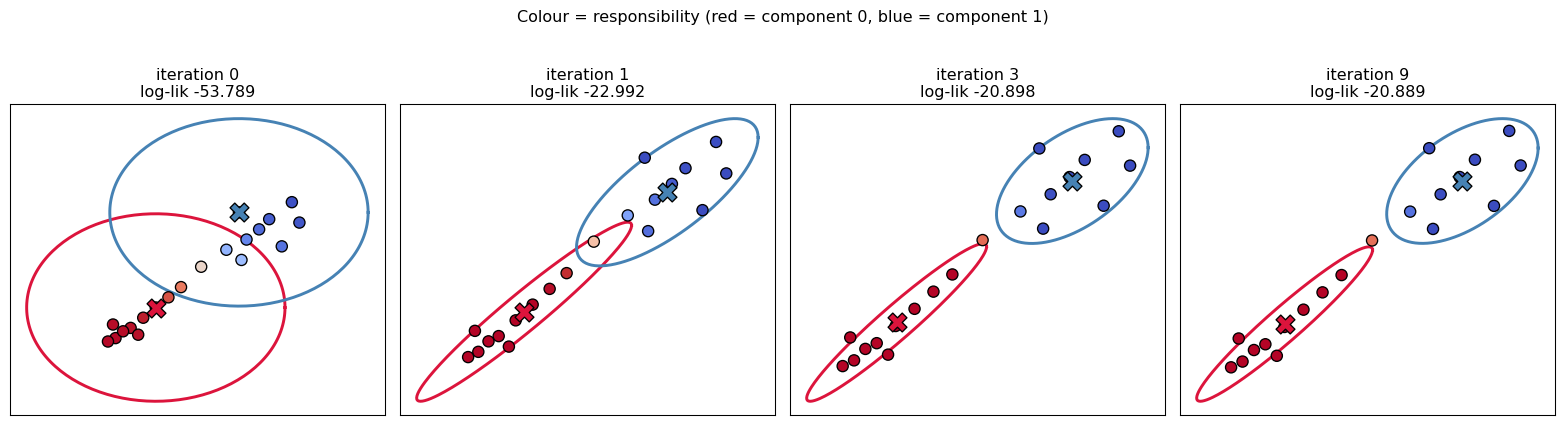

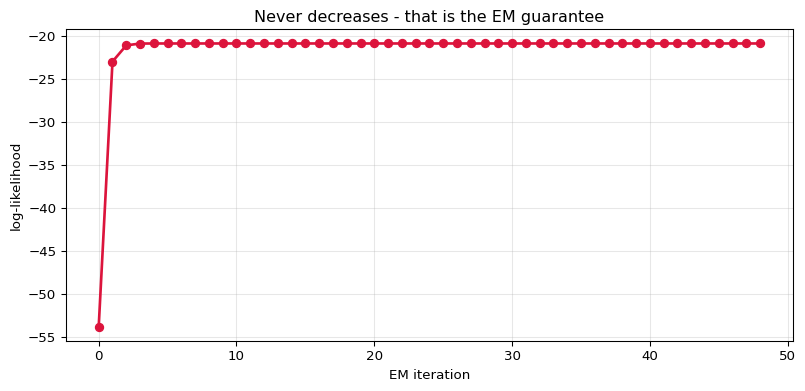

In [8]:
def ellipse(mu, Sig, nsd=2, npts=200):
    th = np.linspace(0, 2*np.pi, npts)
    circ = np.column_stack([np.cos(th), np.sin(th)])
    L = np.linalg.cholesky(Sig)
    return mu + nsd*(circ @ L.T)

shown = [0, 1, 3, min(9, len(snaps)-1)]
fig, axes = plt.subplots(1, len(shown), figsize=(4.1*len(shown), 4.3))
for ax, it in zip(axes, shown):
    mu_s, Sig_s, gam_s = snaps[it]
    ax.scatter(Pz[:,0], Pz[:,1], s=70, c=gam_s[:,0], cmap="coolwarm",
               vmin=0, vmax=1, edgecolor="k", zorder=3)
    for k, col in enumerate(["crimson", "steelblue"]):
        e = ellipse(mu_s[k], Sig_s[k])
        ax.plot(e[:,0], e[:,1], lw=2.2, color=col)
        ax.scatter([mu_s[k,0]], [mu_s[k,1]], marker="X", s=200, c=col,
                   edgecolor="k", zorder=5)
    ax.set(title=f"iteration {it}\nlog-lik {lls[it]:.3f}", xticks=[], yticks=[])
plt.suptitle("Colour = responsibility (red = component 0, blue = component 1)", y=1.02)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(lls, "o-", lw=2, color="crimson")
ax.set(xlabel="EM iteration", ylabel="log-likelihood",
       title="Never decreases - that is the EM guarantee")
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# 4. K-Means Is a Special Case

Take a Gaussian mixture and impose three restrictions:

1. all covariances equal and **spherical**, $\Sigma_k = \sigma^2 I$
2. all mixing weights equal, $\pi_k = 1/K$
3. let $\sigma^2 \to 0$

Then the responsibility of the nearest component tends to 1 and every other to 0 &mdash; **the
soft assignment becomes hard**, and the M-step reduces to "average the points assigned to
me". That is Lloyd's algorithm exactly.

So k-means is not a different method. It is a Gaussian mixture with the covariance thrown
away and the uncertainty rounded off, and the demonstration below is just watching
$\sigma$ shrink.

In [9]:
mu_a = np.array([-1.0, 0.0]); mu_b = np.array([1.0, 0.0])
x_probe = np.array([[0.25, 0.0]])          # slightly nearer to mu_b

print(f"a probe point at {x_probe[0]}, between two centres at "
      f"{mu_a} and {mu_b}\n")
print(f"   Euclidean distance to mu_a: {np.linalg.norm(x_probe[0]-mu_a):.4f}")
print(f"   Euclidean distance to mu_b: {np.linalg.norm(x_probe[0]-mu_b):.4f}")
print(f"   -> k-means would assign it to component b, with no hesitation\n")

# computed in LOG space: at small sigma both densities underflow to 0 in
# float64, and the ratio 0/0 is undefined. Working with log-densities and
# subtracting the max (the log-sum-exp trick) keeps it exact.
def log_gauss(Xm, mu, Sig):
    Dm = len(mu)
    d = Xm - mu
    inv = np.linalg.inv(Sig)
    q = np.einsum("ij,jk,ik->i", d, inv, d)
    return -0.5*q - 0.5*(Dm*np.log(2*np.pi) + np.log(np.linalg.det(Sig)))

print(f"{'sigma':>10}  {'gamma_a':>14}  {'gamma_b':>14}  {'behaviour':>26}")
print("-" * 70)
for s in (2.0, 1.0, 0.5, 0.3, 0.2, 0.1, 0.05, 0.01):
    S = (s**2)*np.eye(2)
    la = np.log(0.5) + float(log_gauss(x_probe, mu_a, S)[0])
    lb = np.log(0.5) + float(log_gauss(x_probe, mu_b, S)[0])
    m_ = max(la, lb)
    ea, eb = np.exp(la-m_), np.exp(lb-m_)
    ga = ea/(ea+eb)
    beh = ("almost 50/50 - very soft" if abs(ga-.5) < .05 else
           "leaning" if abs(ga-.5) < .3 else
           "nearly hard" if abs(ga-.5) < .49 else "HARD, like k-means")
    print(f"{s:>10.2f}  {ga:>14.10f}  {1-ga:>14.10f}  {beh:>26}")
print("-" * 70)
print(f"\nAs sigma shrinks the responsibilities collapse to 0 and 1. In the limit")
print(f"EM performs exactly the assign-and-average steps of Lloyd's algorithm.")

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

km = KMeans(n_clusters=K, n_init=30, random_state=0).fit(Pz)
gm_sph = GaussianMixture(n_components=K, covariance_type="spherical",
                         reg_covar=1e-9, n_init=30, random_state=0).fit(Pz)
gm_full = GaussianMixture(n_components=K, covariance_type="full",
                          n_init=30, random_state=0).fit(Pz)

print(f"\n\non our 20 epochs\n")
print(f"{'method':>28}  {'agreement with k-means':>24}")
print("-" * 56)
kl = km.labels_
for nm, lab in [("GMM, spherical covariance", gm_sph.predict(Pz)),
                ("GMM, full covariance", gm_full.predict(Pz))]:
    ag = max((lab == kl).mean(), (1-lab == kl).mean())
    print(f"{nm:>28}  {ag:>23.1%}")
print("-" * 56)
print(f"\nWith spherical covariances the GMM reproduces k-means almost exactly,")
print(f"as the theory says. With full covariances it is free to disagree.")

a probe point at [0.25 0.  ], between two centres at [-1.  0.] and [1. 0.]

   Euclidean distance to mu_a: 1.2500
   Euclidean distance to mu_b: 0.7500
   -> k-means would assign it to component b, with no hesitation

     sigma         gamma_a         gamma_b                   behaviour
----------------------------------------------------------------------
      2.00    0.4687906266    0.5312093734    almost 50/50 - very soft
      1.00    0.3775406688    0.6224593312                     leaning
      0.50    0.1192029220    0.8807970780                 nearly hard
      0.30    0.0038510324    0.9961489676          HARD, like k-means
      0.20    0.0000037266    0.9999962734          HARD, like k-means
      0.10    0.0000000000    1.0000000000          HARD, like k-means
      0.05    0.0000000000    1.0000000000          HARD, like k-means
      0.01    0.0000000000    1.0000000000          HARD, like k-means
----------------------------------------------------------------------



### The shapes k-means could not find

The K-Means walkthrough showed three failure cases. Two of them &mdash; stretched clusters and
clusters of very different sizes &mdash; are caused precisely by the missing covariance and
the equal mixing weights. A full-covariance GMM handles both.

The third, the two moons, defeats it too: a mixture of Gaussians is still a mixture of
*convex blobs*, and a crescent is not one. Knowing which failures a richer model fixes,
and which it does not, is the useful part.

               dataset    k-means ARI    GMM (full) ARI                 verdict
------------------------------------------------------------------------------
       stretched blobs         0.8650            1.0000           GMM solves it
  very different sizes         0.9750            1.0000           GMM solves it
             two moons         0.2343            0.4606  GMM better, still poor
------------------------------------------------------------------------------


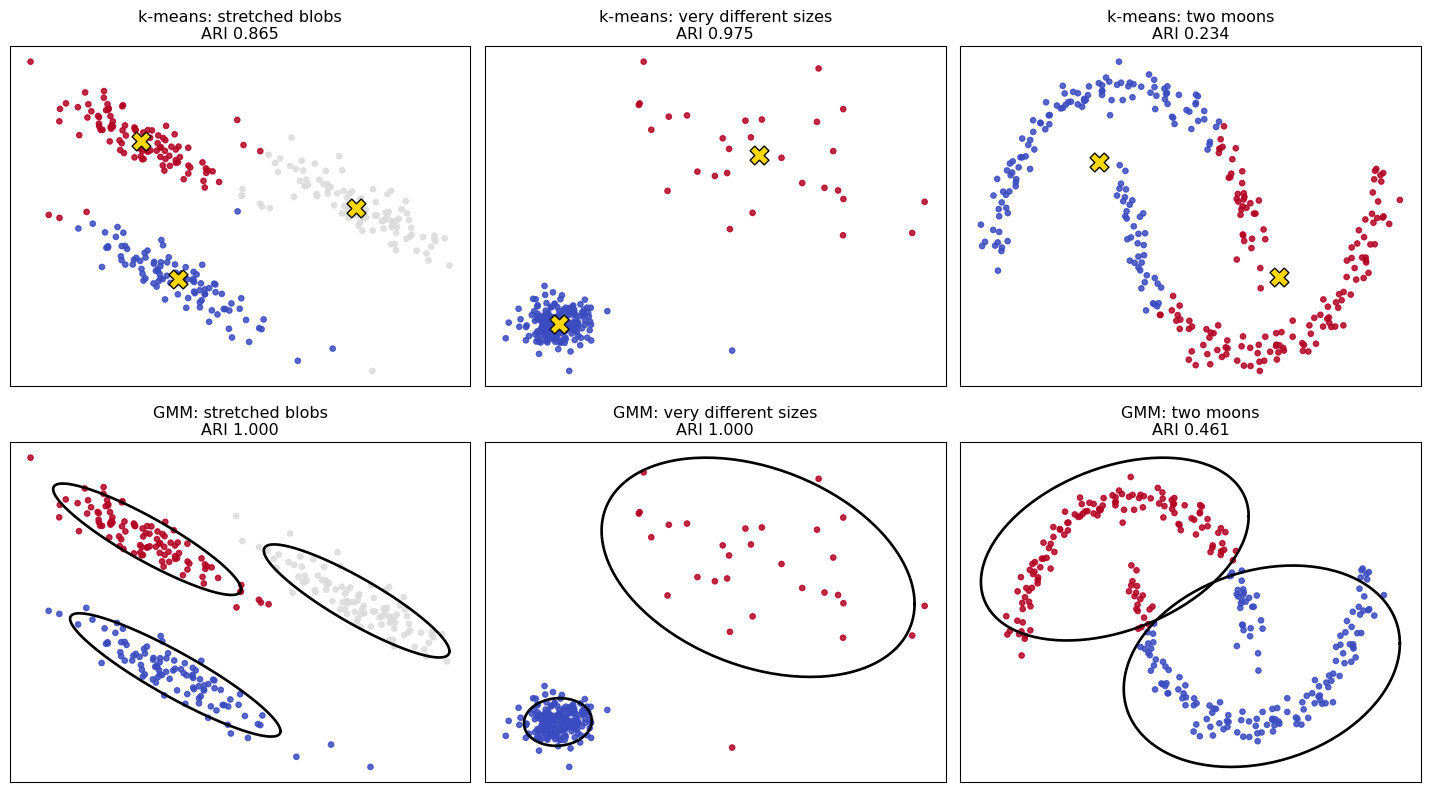

Rows: k-means on top, GMM below. The ellipses show what the covariance
bought - they tilt and stretch to match the data.

Read the three rows separately - they are not the same story:
   stretched blobs      - the covariance fixes it outright (ARI 1.00)
   very different sizes - the mixing weights fix this one too
   two moons            - GMM beats k-means, but 0.46 is still poor.
                          It is NOT solved. Every component is an
                          ellipse and no ellipse is a crescent; GMM
                          merely places its ellipses less badly.

For crescents, rings and manifolds the right tools are density-based
(DBSCAN) or spectral methods - not a richer parametric blob.


In [10]:
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score

rngd = np.random.default_rng(0)
base, lab_a = make_blobs(n_samples=300, centers=3, random_state=2, cluster_std=.6)
aniso = base @ np.array([[1.0, -0.7], [0.0, 0.35]])   # a genuine shear
uneven = np.vstack([rngd.normal(0, .35, (200, 2)), rngd.normal(4, 1.6, (30, 2))])
lab_u = np.r_[np.zeros(200), np.ones(30)]
moons, lab_m = make_moons(n_samples=300, noise=.06, random_state=0)

cases = [("stretched blobs", aniso, lab_a, 3),
         ("very different sizes", uneven, lab_u, 2),
         ("two moons", moons, lab_m, 2)]

print(f"{'dataset':>22}  {'k-means ARI':>13}  {'GMM (full) ARI':>16}  {'verdict':>22}")
print("-" * 78)
for nm, A, lab, k in cases:
    km_ = KMeans(n_clusters=k, n_init=30, random_state=0).fit(A)
    gm_ = GaussianMixture(n_components=k, covariance_type="full", n_init=30,
                          random_state=0).fit(A)
    a_km = adjusted_rand_score(lab, km_.labels_)
    a_gm = adjusted_rand_score(lab, gm_.predict(A))
    if a_gm > 0.9:
        verdict = "GMM solves it"
    elif a_gm > a_km + .15:
        verdict = "GMM better, still poor"
    elif max(a_km, a_gm) < .5:
        verdict = "both fail"
    else:
        verdict = "comparable"
    print(f"{nm:>22}  {a_km:>13.4f}  {a_gm:>16.4f}  {verdict:>22}")
print("-" * 78)

fig, axes = plt.subplots(2, 3, figsize=(15, 8.4))
for j, (nm, A, lab, k) in enumerate(cases):
    km_ = KMeans(n_clusters=k, n_init=30, random_state=0).fit(A)
    gm_ = GaussianMixture(n_components=k, covariance_type="full", n_init=30,
                          random_state=0).fit(A)
    axes[0,j].scatter(A[:,0], A[:,1], c=km_.labels_, cmap="coolwarm", s=16, alpha=.85)
    axes[0,j].scatter(km_.cluster_centers_[:,0], km_.cluster_centers_[:,1],
                      marker="X", s=200, c="gold", edgecolor="k", zorder=5)
    axes[0,j].set(title=f"k-means: {nm}\nARI {adjusted_rand_score(lab, km_.labels_):.3f}")
    axes[1,j].scatter(A[:,0], A[:,1], c=gm_.predict(A), cmap="coolwarm", s=16, alpha=.85)
    for kk in range(k):
        e = ellipse(gm_.means_[kk], gm_.covariances_[kk])
        axes[1,j].plot(e[:,0], e[:,1], lw=2, color="k")
    axes[1,j].set(title=f"GMM: {nm}\nARI {adjusted_rand_score(lab, gm_.predict(A)):.3f}")
    for ax in (axes[0,j], axes[1,j]):
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

print("Rows: k-means on top, GMM below. The ellipses show what the covariance")
print("bought - they tilt and stretch to match the data.")
print("\nRead the three rows separately - they are not the same story:")
print("   stretched blobs      - the covariance fixes it outright (ARI 1.00)")
print("   very different sizes - the mixing weights fix this one too")
print("   two moons            - GMM beats k-means, but 0.46 is still poor.")
print("                          It is NOT solved. Every component is an")
print("                          ellipse and no ellipse is a crescent; GMM")
print("                          merely places its ellipses less badly.")
print("")
print("For crescents, rings and manifolds the right tools are density-based")
print("(DBSCAN) or spectral methods - not a richer parametric blob.")

---
# 5. Choosing $K$ &mdash; Now There Is a Principled Way

Because a GMM is a **probabilistic model**, it assigns a likelihood to the data, and that
allows information criteria that trade fit against complexity:

$$\text{AIC} = 2p - 2\ln\hat{L}
\qquad\qquad
\text{BIC} = p\ln n - 2\ln\hat{L}$$

with $p$ the number of free parameters. Both penalise complexity; BIC penalises harder as
$n$ grows, so it tends to choose fewer components.

K-means has no such option: its inertia falls monotonically with $K$ and cannot be
compared across models. That is a real advantage of the probabilistic formulation, not a
detail.

   K   params    log-likelihood         AIC         BIC   k-means inertia
--------------------------------------------------------------------------
   1        5          -30.7673     71.5345     76.5132           40.0000
   2       11          -21.0083     64.0166     74.9697            6.5191
   3       17           -1.4456     36.8911     53.8186            3.6837
   4       23           13.8214     18.3572     41.2590            2.2182
   5       29           25.0156      7.9687     36.8449            1.6162
   6       35           36.8864     -3.7727     31.0779            1.3230
--------------------------------------------------------------------------

best by AIC: K = 6
best by BIC: K = 6

k-means inertia just keeps falling - it cannot pick K by itself.


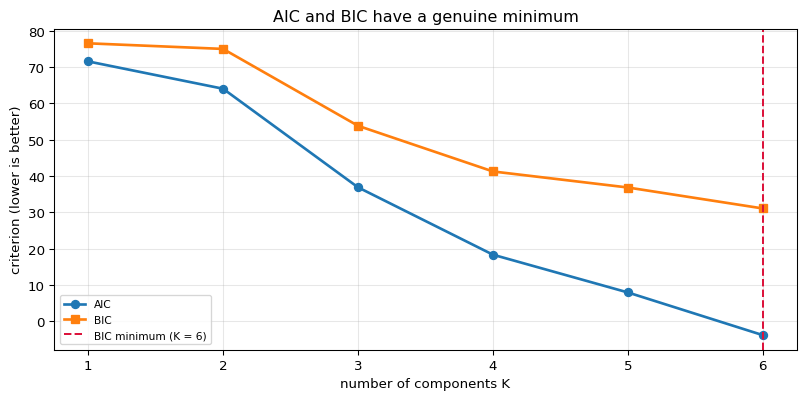

In [11]:
print(f"{'K':>4}  {'params':>7}  {'log-likelihood':>16}  {'AIC':>10}  {'BIC':>10}  "
      f"{'k-means inertia':>16}")
print("-" * 74)
aics, bics, ks = [], [], list(range(1, 7))
for k in ks:
    gm_ = GaussianMixture(n_components=k, covariance_type="full", n_init=30,
                          random_state=0).fit(Pz)
    km_ = KMeans(n_clusters=k, n_init=30, random_state=0).fit(Pz)
    p_ = k*(1 + D + D*(D+1)//2) - 1
    aics.append(gm_.aic(Pz)); bics.append(gm_.bic(Pz))
    print(f"{k:>4}  {p_:>7}  {gm_.score(Pz)*n2:>16.4f}  {gm_.aic(Pz):>10.4f}  "
          f"{gm_.bic(Pz):>10.4f}  {km_.inertia_:>16.4f}")
print("-" * 74)
print(f"\nbest by AIC: K = {ks[int(np.argmin(aics))]}")
print(f"best by BIC: K = {ks[int(np.argmin(bics))]}")
print(f"\nk-means inertia just keeps falling - it cannot pick K by itself.")

fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(ks, aics, "o-", lw=2, label="AIC")
ax.plot(ks, bics, "s-", lw=2, label="BIC")
ax.axvline(ks[int(np.argmin(bics))], ls="--", color="crimson",
           label=f"BIC minimum (K = {ks[int(np.argmin(bics))]})")
ax.set(xlabel="number of components K", ylabel="criterion (lower is better)",
       title="AIC and BIC have a genuine minimum")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# 6. Checking Against scikit-learn

In [12]:
gm = GaussianMixture(n_components=K, covariance_type="full", tol=1e-12,
                     max_iter=1000, n_init=1, reg_covar=1e-6,
                     means_init=Pz[idx0], random_state=0).fit(Pz)

print(f"log-likelihood (total)")
print(f"   ours    : {ll_f:.10f}")
print(f"   sklearn : {gm.score(Pz)*n2:.10f}")
print(f"   MATCH: {np.isclose(ll_f, gm.score(Pz)*n2, atol=1e-6)}\n")

om = np.argsort(mus_r[:, 0]); sm = np.argsort(gm.means_[:, 0])
print("means (sorted, since component numbering is arbitrary)\n")
for a, b in zip(om, sm):
    print(f"   ours {np.round(mus_r[a], 8)}   sklearn {np.round(gm.means_[b], 8)}")
print(f"   MATCH: {np.allclose(mus_r[om], gm.means_[sm], atol=1e-5)}\n")

print("weights\n")
print(f"   ours    : {np.round(pis_r[om], 8)}")
print(f"   sklearn : {np.round(gm.weights_[sm], 8)}")
print(f"   MATCH: {np.allclose(pis_r[om], gm.weights_[sm], atol=1e-5)}\n")

print("covariances\n")
for a, b in zip(om, sm):
    print(f"   ours:")
    show_matrix(Sigs_r[a], "      ", fmt="{:+11.7f}")
    print(f"   sklearn:")
    show_matrix(gm.covariances_[b], "      ", fmt="{:+11.7f}")
    print()
print(f"   MATCH: {np.allclose(Sigs_r[om], gm.covariances_[sm], atol=1e-5)}")

print(f"\nresponsibilities MATCH: "
      f"{np.allclose(gam_f[:, om], gm.predict_proba(Pz)[:, sm], atol=1e-5)}")
print(f"hard assignments MATCH : "
      f"{np.array_equal(np.argsort(om)[gam_f.argmax(1)], np.argsort(sm)[gm.predict(Pz)])}")

from sklearn.metrics import adjusted_rand_score as ari
print(f"\n\nagainst the withheld true labels")
print(f"   GMM adjusted Rand index     : {ari(t2, gm.predict(Pz)):.4f}")
print(f"   k-means adjusted Rand index : {ari(t2, km.labels_):.4f}")

log-likelihood (total)
   ours    : -20.8890185000
   sklearn : -20.8890185000
   MATCH: True

means (sorted, since component numbering is arbitrary)

   ours [-0.826  -0.8162]   sklearn [-0.826  -0.8162]
   ours [0.9944 0.9826]   sklearn [0.9944 0.9826]
   MATCH: True

weights

   ours    : [0.5462 0.4538]
   sklearn : [0.5462 0.4538]
   MATCH: True

covariances

   ours:
       (2, 2) =
            0 |  +0.2018692   +0.2084080
            1 |  +0.2084080   +0.2345665
   sklearn:
       (2, 2) =
            0 |  +0.2018693   +0.2084081
            1 |  +0.2084081   +0.2345666

   ours:
       (2, 2) =
            0 |  +0.1507188   +0.0807771
            1 |  +0.0807771   +0.1539773
   sklearn:
       (2, 2) =
            0 |  +0.1507188   +0.0807771
            1 |  +0.0807771   +0.1539772

   MATCH: True

responsibilities MATCH: True
hard assignments MATCH : True


against the withheld true labels
   GMM adjusted Rand index     : 0.7996
   k-means adjusted Rand index : 0.6200


---
# 7. Summary

| | K-Means | Gaussian Mixture |
|---|---|---|
| Cluster is | a point | a distribution |
| Assignment | hard, $\{0,1\}$ | **soft**, $\gamma_{ik}\in[0,1]$ |
| Shape | spherical only | any ellipse, per component |
| Sizes | implicitly equal | $\pi_k$ per component |
| Objective | inertia | log-likelihood |
| Choosing $K$ | elbow / silhouette | **AIC / BIC** |
| Parameters ($K$=2, $D$=2) | 4 | 11 |
| Cost per iteration | $O(nKD)$ | $O(nKD^2)$ + inverses |

**The one idea:** EM is Lloyd's algorithm with the hard assignment replaced by a
probability. Both alternate "assign, then refit"; only the strength of the assignment
differs, and letting it be fractional is what admits covariance, unequal sizes, and a
statement of confidence.

**The cost of the extra power:** more parameters to estimate, so more data needed, plus a
genuine failure mode &mdash; a component can collapse onto a single point, driving
$\lvert\Sigma\rvert \to 0$ and the likelihood to infinity. That is why `reg_covar` exists:
it adds a small constant to the diagonal to stop it.

**What it still cannot do:** every component is convex. On the two-moons data above GMM
scores better than k-means (0.46 vs 0.23) but still fails - no ellipse is a crescent. The
extra flexibility buys shape and orientation, not topology.

**What is deliberately left out:** the proof that EM never decreases the likelihood (via
Jensen's inequality and the ELBO), the connection to variational inference, Dirichlet
process mixtures that infer $K$, and the tied/diagonal covariance variants that sit
between spherical and full.